In [1]:
# Add relevant Jupyter notebook extensions 

In [2]:
# You can double-check your Python path like this...
import sys  
print(sys.path)
from pathlib import Path

['C:\\Program Files\\WindowsApps\\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\\python311.zip', 'C:\\Program Files\\WindowsApps\\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\\DLLs', 'C:\\Program Files\\WindowsApps\\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\\Lib', 'C:\\Program Files\\WindowsApps\\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0', 'c:\\Users\\dp240\\b1-coding-practical-mt24\\.venv', '', 'c:\\Users\\dp240\\b1-coding-practical-mt24\\.venv\\Lib\\site-packages']


# Simulate closed-loop
After implementing your control functionality, you can simulate the closed-loop with code that looks something like this...

Mission loaded: 100 data points


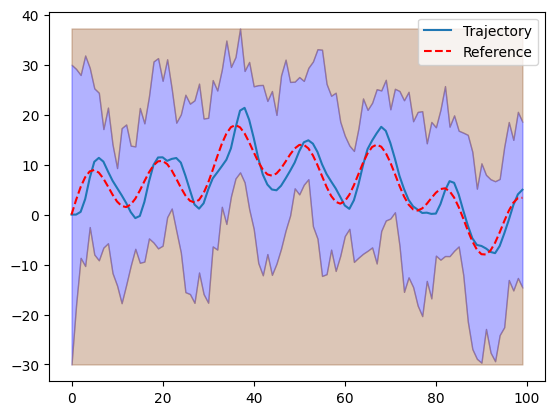

In [3]:
project_root = Path.cwd()

if not (project_root / "uuv_mission").is_dir():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from uuv_mission.dynamic import Submarine, Mission, ClosedLoop
from uuv_mission.control import PDController

# Create submarine and controller
sub = Submarine()
controller = PDController(kp=0.15, kd=0.6)

# Connect controller to submarine
closed_loop = ClosedLoop(sub, controller)

# Load mission data
mission = Mission.from_csv(
    str(project_root / "data" / "mission.csv")
)

# Verify mission loaded correctly
print("Mission loaded:", len(mission.reference), "data points")

# Run simulation
trajectory = closed_loop.simulate_with_random_disturbances(mission)

# Plot result
trajectory.plot_completed_mission(mission)